<a href="https://colab.research.google.com/github/sats-11/sats-11-web-projects/blob/main/Emotion_%26_Mental_Health_Detection_Word2Vec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q gensim nltk

In [3]:
import pandas as pd
import numpy as np
import re
import time
import nltk

from gensim.models import Word2Vec
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [8]:
from google.colab import files

uploaded = files.upload()

Saving emotion_dataset_raw.csv to emotion_dataset_raw (1).csv


In [9]:
import io

filename = next(iter(uploaded))

emotion_df = pd.read_csv(
    io.BytesIO(uploaded[filename])
)

print("Dataset shape:", emotion_df.shape)
print("\nColumn names:")
print(emotion_df.columns.tolist())

display(emotion_df.head())

Dataset shape: (34792, 2)

Column names:
['Emotion', 'Text']


,Emotion,Text
0,neutral,Why ?
1,joy,Sage Act upgrade on my to do list for tommorow.
2,sadness,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...
3,joy,Such an eye ! The true hazel eye-and so brill...
4,joy,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...


In [10]:
# Keep the required columns
emotion_df = emotion_df[["Text", "Emotion"]].copy()

# Remove missing and empty records
emotion_df = emotion_df.dropna(
    subset=["Text", "Emotion"]
)

emotion_df["Text"] = emotion_df["Text"].astype(str).str.strip()
emotion_df["Emotion"] = emotion_df["Emotion"].astype(str).str.strip()

emotion_df = emotion_df[
    (emotion_df["Text"] != "") &
    (emotion_df["Emotion"] != "")
]

# Remove exact duplicate text-label pairs
emotion_df = emotion_df.drop_duplicates(
    subset=["Text", "Emotion"]
).reset_index(drop=True)

print("Cleaned dataset shape:", emotion_df.shape)
print("\nClass distribution:")
print(emotion_df["Emotion"].value_counts())

print("\nMissing values:")
print(emotion_df.isnull().sum())

Cleaned dataset shape: (31147, 2)

Class distribution:
Emotion
joy         10464
sadness      6174
fear         4262
surprise     4015
anger        3775
neutral      1458
disgust       855
shame         144
Name: count, dtype: int64

Missing values:
Text       0
Emotion    0
dtype: int64


In [14]:

import re
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required resources (safe to rerun)
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

# Initialize tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

# Preserve negation words because they can change emotion meaning
negation_words = {
    "no", "not", "nor", "never", "neither", "nobody",
    "nothing", "nowhere", "cannot", "without"
}
stop_words = stop_words - negation_words

def preprocess_text(text):
    text = str(text).lower()

    # Remove URLs, mentions, and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"<.*?>", " ", text)

    # Keep letters, apostrophes, and spaces
    text = re.sub(r"[^a-z'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)

    # Remove stopwords while retaining negation
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]

    return tokens

df["tokens"] = df["Text"].apply(preprocess_text)

# Inspect the preprocessing results
print("Original text:")
print(df["Text"].iloc[0])

print("\nProcessed tokens:")
print(df["tokens"].iloc[0])

print("\nEmpty processed texts:", (df["tokens"].str.len() == 0).sum())
print("Dataset shape:", df.shape)


Original text:
 Why ? 

Processed tokens:
[]

Empty processed texts: 311
Dataset shape: (34792, 3)


In [16]:

# Keep potentially meaningful words for emotion classification
keep_words = {
    "no", "not", "nor", "never", "neither", "nobody",
    "nothing", "nowhere", "cannot", "without",
    "why", "what", "who", "how", "when", "where"
}

stop_words = set(stopwords.words("english")) - keep_words

# Reprocess the text using the updated stopword list
df["tokens"] = df["Text"].apply(preprocess_text)

print("Original text:", repr(df["Text"].iloc[0]))
print("Processed tokens:", df["tokens"].iloc[0])
print("Empty processed texts:", (df["tokens"].str.len() == 0).sum())
print("Dataset shape:", df.shape)


Original text: ' Why ? '
Processed tokens: ['why']
Empty processed texts: 125
Dataset shape: (34792, 3)


In [17]:

from sklearn.model_selection import train_test_split

# Remove rows that have no usable tokens
df_model = df[df["tokens"].str.len() > 0].copy()

print("Rows before filtering:", len(df))
print("Rows removed:", len(df) - len(df_model))
print("Rows remaining:", len(df_model))

# Split before training Word2Vec to avoid vocabulary leakage
X_train, X_test, y_train, y_test = train_test_split(
    df_model["tokens"],
    df_model["Emotion"],
    test_size=0.20,
    random_state=42,
    stratify=df_model["Emotion"]
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())


Rows before filtering: 34792
Rows removed: 125
Rows remaining: 34667

Training samples: 27733
Testing samples: 6934

Training class distribution:
Emotion
joy         8833
sadness     5377
fear        4328
anger       3435
surprise    3250
neutral     1708
disgust      685
shame        117
Name: count, dtype: int64


In [12]:

print("Is df defined?", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
else:
    print("Dataset is not loaded. Please reload your CSV.")


Is df defined? False
Dataset is not loaded. Please reload your CSV.


In [13]:

from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())


Saving emotion_dataset_raw.csv to emotion_dataset_raw (2).csv
Dataset loaded successfully!
Shape: (34792, 2)
Columns: ['Emotion', 'Text']
   Emotion                                               Text
0  neutral                                             Why ? 
1      joy    Sage Act upgrade on my to do list for tommorow.
2  sadness  ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...
3      joy   Such an eye ! The true hazel eye-and so brill...
4      joy  @Iluvmiasantos ugh babe.. hugggzzz for u .!  b...


In [18]:

def preprocess_text(text):
    text = str(text).lower().strip()

    # Remove URLs, mentions, and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"<.*?>", " ", text)

    # Remove punctuation and extra spaces
    text = re.sub(r"[^a-z'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)

    # Remove standalone apostrophes and expand common contractions
    expanded = []
    for token in tokens:
        if token in {"can't", "cannot"}:
            expanded.extend(["can", "not"])
        elif token == "won't":
            expanded.extend(["will", "not"])
        elif token.endswith("n't") and len(token) > 3:
            expanded.extend([token[:-3], "not"])
        else:
            expanded.append(token)

    # Preserve short meaningful words and negation
    tokens = [
        lemmatizer.lemmatize(token)
        for token in expanded
        if token not in stop_words
        and (len(token) > 1 or token in negation_words)
        and token != "'"
    ]

    return tokens

# Reprocess the dataset
df["tokens"] = df["Text"].apply(preprocess_text)

print("Original text:", repr(df["Text"].iloc[0]))
print("Processed tokens:", df["tokens"].iloc[0])
print("Empty processed texts:", (df["tokens"].str.len() == 0).sum())
print("Dataset shape:", df.shape)


Original text: ' Why ? '
Processed tokens: ['why']
Empty processed texts: 125
Dataset shape: (34792, 3)


In [19]:

from gensim.models import Word2Vec
import time

# Prepare training corpus
train_sentences = X_train.tolist()

# Train Skip-gram Word2Vec
start_time = time.time()

w2v_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,  # Embedding dimension
    window=5,         # Context window
    min_count=2,      # Ignore very rare words
    workers=4,
    sg=1,             # 1 = Skip-gram; 0 = CBOW
    negative=10,
    epochs=10,
    seed=42
)

w2v_training_time = time.time() - start_time

print("Word2Vec training completed!")
print("Vocabulary size:", len(w2v_model.wv))
print("Embedding dimensions:", w2v_model.vector_size)
print("Training time:", round(w2v_training_time, 2), "seconds")

# Inspect a word embedding
word = "happy"
if word in w2v_model.wv:
    print("\nFirst 10 values of the 'happy' embedding:")
    print(w2v_model.wv[word][:10])
else:
    print("\n'happy' is not in the vocabulary; try another common word.")


Word2Vec training completed!
Vocabulary size: 12055
Embedding dimensions: 100
Training time: 33.98 seconds

First 10 values of the 'happy' embedding:
[ 0.39557844 -0.7622495   0.21956152  0.23647003  0.5492613   0.13081236
 -0.15956868 -0.14730372 -0.12860104  0.1094569 ]


In [20]:

import numpy as np

def document_vector(tokens, model, vector_size=100):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    # Return a zero vector if no words are in the vocabulary
    if len(vectors) == 0:
        return np.zeros(vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0)

# Convert training and testing texts into vectors
X_train_w2v = np.vstack([
    document_vector(tokens, w2v_model)
    for tokens in X_train
])

X_test_w2v = np.vstack([
    document_vector(tokens, w2v_model)
    for tokens in X_test
])

print("Training feature shape:", X_train_w2v.shape)
print("Testing feature shape:", X_test_w2v.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

print("\nFirst 10 features of the first training sample:")
print(X_train_w2v[0][:10])

print("\nZero training vectors:",
      np.all(X_train_w2v == 0, axis=1).sum())

print("Zero testing vectors:",
      np.all(X_test_w2v == 0, axis=1).sum())


Training feature shape: (27733, 100)
Testing feature shape: (6934, 100)
Training labels shape: (27733,)
Testing labels shape: (6934,)

First 10 features of the first training sample:
[-0.02503928  0.07714061  0.09584878 -0.07745732 -0.23863903  0.36411878
 -0.2164217   0.15514983 -0.29423872 -0.22181666]

Zero training vectors: 13
Zero testing vectors: 4


In [22]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Three Logistic Regression configurations
lr_models = {
    "Logistic Regression - Multinomial": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            random_state=42
        )
    ),

    "Logistic Regression - OvR": make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            LogisticRegression(
                solver="lbfgs",
                max_iter=2000,
                random_state=42
            )
        )
    ),

    "Logistic Regression - Balanced": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
}

lr_results = []
lr_trained_models = {}

for name, model in lr_models.items():
    print(f"\nTraining: {name}")
    start_time = time.time()

    model.fit(X_train_w2v, y_train)
    y_pred = model.predict(X_test_w2v)

    elapsed = time.time() - start_time
    lr_trained_models[name] = model

    lr_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Training + Prediction Time (s)": round(elapsed, 2)
    })

lr_results_df = pd.DataFrame(lr_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

print("\n=== Logistic Regression Comparison ===")
display(lr_results_df.round(4))

# Detailed report for the best Macro-F1 model
best_lr_name = lr_results_df.loc[0, "Model"]
best_lr_model = lr_trained_models[best_lr_name]
best_lr_predictions = best_lr_model.predict(X_test_w2v)

print("\nBest Logistic Regression:", best_lr_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_lr_predictions,
    zero_division=0
))



Training: Logistic Regression - Multinomial

Training: Logistic Regression - OvR

Training: Logistic Regression - Balanced

=== Logistic Regression Comparison ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,Logistic Regression - Multinomial,0.5131,0.4928,0.3616,0.3828,14.46
1,Logistic Regression - OvR,0.5081,0.5554,0.3508,0.3728,7.02
2,Logistic Regression - Balanced,0.4318,0.3795,0.4676,0.3675,3.44



Best Logistic Regression: Logistic Regression - Multinomial

Classification Report:
              precision    recall  f1-score   support

       anger       0.43      0.38      0.41       859
     disgust       0.22      0.05      0.08       171
        fear       0.55      0.45      0.49      1082
         joy       0.53      0.78      0.63      2209
     neutral       0.70      0.49      0.58       427
     sadness       0.45      0.44      0.45      1345
       shame       0.50      0.03      0.06        29
    surprise       0.56      0.27      0.36       812

    accuracy                           0.51      6934
   macro avg       0.49      0.36      0.38      6934
weighted avg       0.51      0.51      0.49      6934



In [23]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

svm_models = {
    "Linear SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=10000,
            random_state=42
        )
    ),

    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            class_weight="balanced"
        )
    ),

    "Polynomial SVM (degree 3)": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="poly",
            degree=3,
            C=1.0,
            class_weight="balanced"
        )
    ),

    "Sigmoid SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="sigmoid",
            C=1.0,
            class_weight="balanced"
        )
    )
}

svm_results = []
svm_trained_models = {}

for name, model in svm_models.items():
    print(f"\nTraining: {name}")
    start_time = time.time()

    model.fit(X_train_w2v, y_train)
    y_pred = model.predict(X_test_w2v)

    elapsed = time.time() - start_time
    svm_trained_models[name] = model

    svm_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Training + Prediction Time (s)": round(elapsed, 2)
    })

svm_results_df = pd.DataFrame(svm_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

print("\n=== SVM Comparison: Word2Vec ===")
display(svm_results_df.round(4))

# Detailed report for the best SVM by Macro-F1
best_svm_name = svm_results_df.loc[0, "Model"]
best_svm_model = svm_trained_models[best_svm_name]
best_svm_predictions = best_svm_model.predict(X_test_w2v)

print("\nBest SVM:", best_svm_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_svm_predictions,
    zero_division=0
))



Training: Linear SVM

Training: RBF SVM

Training: Polynomial SVM (degree 3)

Training: Sigmoid SVM

=== SVM Comparison: Word2Vec ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,RBF SVM,0.5216,0.4502,0.5147,0.4517,195.44
1,Polynomial SVM (degree 3),0.4810,0.4816,0.4620,0.4304,211.56
2,Linear SVM,0.4622,0.3895,0.4647,0.3782,14.52
3,Sigmoid SVM,0.2776,0.2432,0.2923,0.2220,167.17



Best SVM: RBF SVM

Classification Report:
              precision    recall  f1-score   support

       anger       0.44      0.51      0.47       859
     disgust       0.11      0.49      0.19       171
        fear       0.64      0.50      0.56      1082
         joy       0.73      0.57      0.64      2209
     neutral       0.63      0.72      0.67       427
     sadness       0.52      0.43      0.47      1345
       shame       0.09      0.41      0.15        29
    surprise       0.44      0.48      0.46       812

    accuracy                           0.52      6934
   macro avg       0.45      0.51      0.45      6934
weighted avg       0.58      0.52      0.54      6934



In [26]:

print("X_train_w2v:", X_train_w2v.shape, X_train_w2v.dtype)
print("X_test_w2v:", X_test_w2v.shape, X_test_w2v.dtype)

print("\ny_train type:", type(y_train))
print("y_train shape:", y_train.shape)
print("y_train sample:", y_train.head().tolist())

print("\ny_test type:", type(y_test))
print("y_test shape:", y_test.shape)
print("y_test sample:", y_test.head().tolist())


X_train_w2v: (27733, 100) float32
X_test_w2v: (6934, 100) float32

y_train type: <class 'pandas.core.series.Series'>
y_train shape: (27733,)
y_train sample: ['fear', 'sadness', 'joy', 'fear', 'joy']

y_test type: <class 'pandas.core.series.Series'>
y_test shape: (6934,)
y_test sample: ['fear', 'joy', 'disgust', 'surprise', 'joy']


In [30]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Scale the features
knn_scaler = StandardScaler()
Xtr_scaled = knn_scaler.fit_transform(X_train_w2v)
Xte_scaled = knn_scaler.transform(X_test_w2v)

# Train a fresh KNN model
knn_test_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

knn_test_model.fit(Xtr_scaled, y_train)

print("KNN training completed.")
print("First 10 predictions:", knn_test_model.predict(Xte_scaled[:10]))


KNN training completed.
First 10 predictions: ['anger' 'joy' 'anger' 'joy' 'sadness' 'surprise' 'joy' 'fear' 'anger'
 'fear']


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Prediction Time (s)
0,"KNN - k=5, Distance Weighted",0.5446,0.4532,0.4155,0.427,4.08



Classification Report:
              precision    recall  f1-score   support

       anger       0.44      0.48      0.46       859
     disgust       0.14      0.11      0.13       171
        fear       0.57      0.64      0.60      1082
         joy       0.62      0.69      0.65      2209
     neutral       0.81      0.59      0.68       427
     sadness       0.49      0.44      0.46      1345
       shame       0.12      0.03      0.05        29
    surprise       0.42      0.33      0.37       812

    accuracy                           0.54      6934
   macro avg       0.45      0.42      0.43      6934
weighted avg       0.54      0.54      0.54      6934



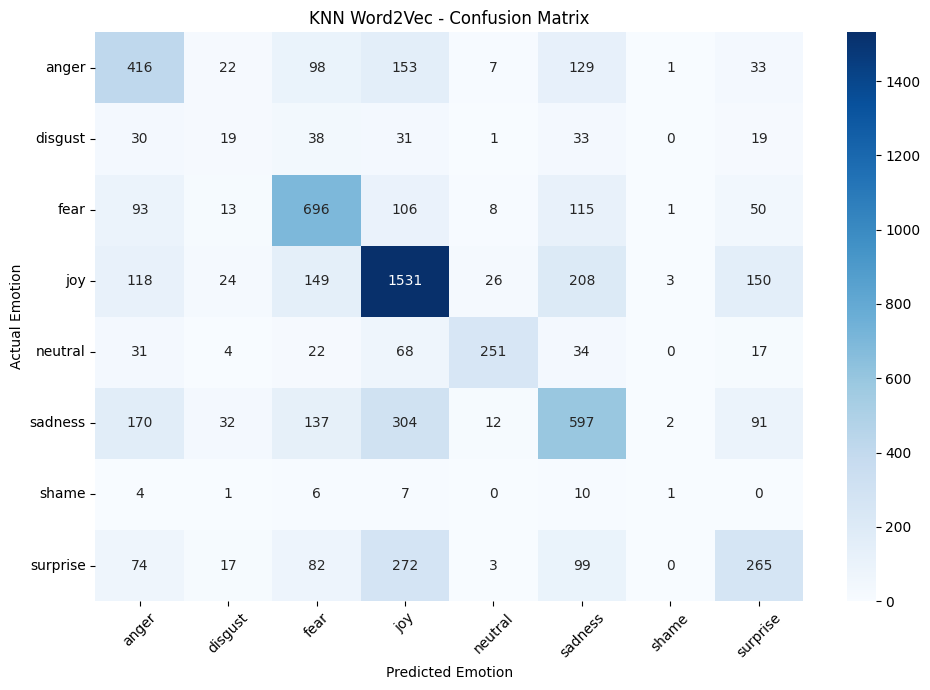

In [31]:

import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Measure prediction time separately
start_time = time.time()
knn_predictions = knn_test_model.predict(Xte_scaled)
prediction_time = time.time() - start_time

# Calculate metrics
knn_metrics = {
    "Model": "KNN - k=5, Distance Weighted",
    "Accuracy": accuracy_score(y_test, knn_predictions),
    "Macro Precision": precision_score(
        y_test, knn_predictions, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, knn_predictions, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, knn_predictions, average="macro", zero_division=0
    ),
    "Prediction Time (s)": round(prediction_time, 2)
}

display(pd.DataFrame([knn_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, knn_predictions, zero_division=0
))

# Confusion matrix
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, knn_predictions, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("KNN Word2Vec - Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Base models
lr_hard = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

svm_hard = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    )
)

rf_hard = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Hard Voting ensemble
hard_voting_model = VotingClassifier(
    estimators=[
        ("lr", lr_hard),
        ("svm", svm_hard),
        ("rf", rf_hard)
    ],
    voting="hard",
    n_jobs=-1
)

# Train and evaluate
start_time = time.time()

hard_voting_model.fit(X_train_w2v, y_train)
hard_predictions = hard_voting_model.predict(X_test_w2v)

hard_total_time = time.time() - start_time

# Calculate metrics
hard_results = pd.DataFrame([{
    "Model": "Hard Voting (LR + Linear SVM + RF)",
    "Accuracy": accuracy_score(y_test, hard_predictions),
    "Macro Precision": precision_score(
        y_test, hard_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, hard_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, hard_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(hard_total_time, 2)
}])

display(hard_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, hard_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,Hard Voting (LR + Linear SVM + RF),0.4709,0.403,0.4758,0.3885,128.49



Classification Report:
              precision    recall  f1-score   support

       anger       0.40      0.43      0.41       859
     disgust       0.11      0.40      0.17       171
        fear       0.56      0.43      0.49      1082
         joy       0.62      0.62      0.62      2209
     neutral       0.45      0.61      0.52       427
     sadness       0.51      0.33      0.41      1345
       shame       0.05      0.66      0.09        29
    surprise       0.51      0.33      0.40       812

    accuracy                           0.47      6934
   macro avg       0.40      0.48      0.39      6934
weighted avg       0.53      0.47      0.49      6934



In [33]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Logistic Regression
lr_soft = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

# SVM with probability estimates enabled
svm_soft = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="linear",
        probability=True,
        class_weight="balanced",
        random_state=42
    )
)

# Random Forest
rf_soft = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Soft Voting ensemble
soft_voting_model = VotingClassifier(
    estimators=[
        ("lr", lr_soft),
        ("svm", svm_soft),
        ("rf", rf_soft)
    ],
    voting="soft",
    n_jobs=-1
)

start_time = time.time()

soft_voting_model.fit(X_train_w2v, y_train)
soft_predictions = soft_voting_model.predict(X_test_w2v)

soft_total_time = time.time() - start_time

soft_results = pd.DataFrame([{
    "Model": "Soft Voting (LR + SVM + RF)",
    "Accuracy": accuracy_score(y_test, soft_predictions),
    "Macro Precision": precision_score(
        y_test, soft_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, soft_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, soft_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(soft_total_time, 2)
}])

display(soft_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, soft_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,Soft Voting (LR + SVM + RF),0.5779,0.4834,0.4543,0.4606,2052.83



Classification Report:
              precision    recall  f1-score   support

       anger       0.54      0.49      0.51       859
     disgust       0.16      0.15      0.16       171
        fear       0.69      0.60      0.64      1082
         joy       0.59      0.79      0.67      2209
     neutral       0.67      0.60      0.64       427
     sadness       0.54      0.50      0.52      1345
       shame       0.12      0.21      0.16        29
    surprise       0.55      0.30      0.39       812

    accuracy                           0.58      6934
   macro avg       0.48      0.45      0.46      6934
weighted avg       0.58      0.58      0.57      6934



In [34]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

lr_weighted = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

svm_weighted = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="linear",
        probability=True,
        class_weight="balanced",
        random_state=42
    )
)

rf_weighted = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

weighted_voting_model = VotingClassifier(
    estimators=[
        ("lr", lr_weighted),
        ("svm", svm_weighted),
        ("rf", rf_weighted)
    ],
    voting="soft",
    weights=[3, 2, 1],
    n_jobs=-1
)

start_time = time.time()

weighted_voting_model.fit(X_train_w2v, y_train)
weighted_predictions = weighted_voting_model.predict(X_test_w2v)

weighted_total_time = time.time() - start_time

weighted_results = pd.DataFrame([{
    "Model": "Weighted Soft Voting (LR:SVM:RF = 3:2:1)",
    "Accuracy": accuracy_score(y_test, weighted_predictions),
    "Macro Precision": precision_score(
        y_test, weighted_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, weighted_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, weighted_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(weighted_total_time, 2)
}])

display(weighted_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, weighted_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,Weighted Soft Voting (LR:SVM:RF = 3:2:1),0.5314,0.435,0.459,0.4282,2071.12



Classification Report:
              precision    recall  f1-score   support

       anger       0.48      0.46      0.47       859
     disgust       0.14      0.23      0.17       171
        fear       0.63      0.52      0.57      1082
         joy       0.60      0.70      0.65      2209
     neutral       0.58      0.61      0.59       427
     sadness       0.51      0.44      0.47      1345
       shame       0.06      0.38      0.11        29
    surprise       0.49      0.33      0.39       812

    accuracy                           0.53      6934
   macro avg       0.44      0.46      0.43      6934
weighted avg       0.54      0.53      0.53      6934



In [35]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Base estimators
lr_stack = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

svm_stack = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    )
)

rf_stack = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Meta-classifier learns how to combine base-model predictions
stacking_model = StackingClassifier(
    estimators=[
        ("lr", lr_stack),
        ("svm", svm_stack),
        ("rf", rf_stack)
    ],
    final_estimator=LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    cv=3,
    stack_method="auto",
    n_jobs=-1,
    passthrough=False
)

start_time = time.time()

stacking_model.fit(X_train_w2v, y_train)
stack_predictions = stacking_model.predict(X_test_w2v)

stack_total_time = time.time() - start_time

stack_results = pd.DataFrame([{
    "Model": "Stacking (LR + Linear SVM + RF)",
    "Accuracy": accuracy_score(y_test, stack_predictions),
    "Macro Precision": precision_score(
        y_test, stack_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, stack_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, stack_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(stack_total_time, 2)
}])

display(stack_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, stack_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,Stacking (LR + Linear SVM + RF),0.5358,0.4763,0.5592,0.462,223.48



Classification Report:
              precision    recall  f1-score   support

       anger       0.52      0.48      0.49       859
     disgust       0.10      0.46      0.17       171
        fear       0.74      0.59      0.66      1082
         joy       0.74      0.60      0.66      2209
     neutral       0.67      0.66      0.67       427
     sadness       0.54      0.45      0.49      1345
       shame       0.06      0.79      0.11        29
    surprise       0.43      0.45      0.44       812

    accuracy                           0.54      6934
   macro avg       0.48      0.56      0.46      6934
weighted avg       0.62      0.54      0.57      6934



In [36]:

import time
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert token lists back into text for TF-IDF
X_train_text = [" ".join(tokens) for tokens in X_train]
X_test_text = [" ".join(tokens) for tokens in X_test]

# Fit TF-IDF on training data only
tfidf_vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)
print("Word2Vec training shape:", X_train_w2v.shape)
print("Word2Vec testing shape:", X_test_w2v.shape)


TF-IDF training shape: (27733, 30000)
TF-IDF testing shape: (6934, 30000)
Word2Vec training shape: (27733, 100)
Word2Vec testing shape: (6934, 100)


In [37]:

from scipy.sparse import csr_matrix, hstack

# Convert dense Word2Vec arrays to sparse matrices
X_train_w2v_sparse = csr_matrix(X_train_w2v)
X_test_w2v_sparse = csr_matrix(X_test_w2v)

# Combine features horizontally
X_train_hybrid = hstack(
    [X_train_tfidf, X_train_w2v_sparse],
    format="csr"
)

X_test_hybrid = hstack(
    [X_test_tfidf, X_test_w2v_sparse],
    format="csr"
)

print("Hybrid training shape:", X_train_hybrid.shape)
print("Hybrid testing shape:", X_test_hybrid.shape)
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))


Hybrid training shape: (27733, 30100)
Hybrid testing shape: (6934, 30100)
Training labels: 27733
Testing labels: 6934


In [38]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

hybrid_lr = LogisticRegression(
    solver="lbfgs",
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

hybrid_lr.fit(X_train_hybrid, y_train)
hybrid_lr_predictions = hybrid_lr.predict(X_test_hybrid)

hybrid_lr_time = time.time() - start_time

hybrid_lr_results = pd.DataFrame([{
    "Model": "TF-IDF + Word2Vec - Logistic Regression",
    "Accuracy": accuracy_score(y_test, hybrid_lr_predictions),
    "Macro Precision": precision_score(
        y_test, hybrid_lr_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, hybrid_lr_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, hybrid_lr_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(hybrid_lr_time, 2)
}])

display(hybrid_lr_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, hybrid_lr_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,TF-IDF + Word2Vec - Logistic Regression,0.6044,0.5842,0.6379,0.6017,63.79



Classification Report:
              precision    recall  f1-score   support

       anger       0.54      0.61      0.57       859
     disgust       0.20      0.46      0.28       171
        fear       0.70      0.65      0.67      1082
         joy       0.75      0.65      0.69      2209
     neutral       0.52      0.68      0.59       427
     sadness       0.60      0.52      0.55      1345
       shame       0.88      1.00      0.94        29
    surprise       0.49      0.55      0.52       812

    accuracy                           0.60      6934
   macro avg       0.58      0.64      0.60      6934
weighted avg       0.63      0.60      0.61      6934



In [39]:

import time
import pandas as pd

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

hybrid_svm = LinearSVC(
    C=1.0,
    class_weight="balanced",
    max_iter=10000,
    random_state=42
)

start_time = time.time()

hybrid_svm.fit(X_train_hybrid, y_train)
hybrid_svm_predictions = hybrid_svm.predict(X_test_hybrid)

hybrid_svm_time = time.time() - start_time

hybrid_svm_results = pd.DataFrame([{
    "Model": "TF-IDF + Word2Vec - Linear SVM",
    "Accuracy": accuracy_score(y_test, hybrid_svm_predictions),
    "Macro Precision": precision_score(
        y_test, hybrid_svm_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, hybrid_svm_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, hybrid_svm_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(hybrid_svm_time, 2)
}])

display(hybrid_svm_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, hybrid_svm_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,TF-IDF + Word2Vec - Linear SVM,0.6397,0.6209,0.6445,0.6313,54.51



Classification Report:
              precision    recall  f1-score   support

       anger       0.58      0.60      0.59       859
     disgust       0.28      0.35      0.31       171
        fear       0.73      0.72      0.73      1082
         joy       0.72      0.72      0.72      2209
     neutral       0.59      0.68      0.63       427
     sadness       0.63      0.55      0.59      1345
       shame       0.94      1.00      0.97        29
    surprise       0.51      0.53      0.52       812

    accuracy                           0.64      6934
   macro avg       0.62      0.64      0.63      6934
weighted avg       0.64      0.64      0.64      6934



In [40]:

import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

hybrid_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

hybrid_rf.fit(X_train_hybrid, y_train)
hybrid_rf_predictions = hybrid_rf.predict(X_test_hybrid)

hybrid_rf_time = time.time() - start_time

hybrid_rf_results = pd.DataFrame([{
    "Model": "TF-IDF + Word2Vec - Random Forest",
    "Accuracy": accuracy_score(y_test, hybrid_rf_predictions),
    "Macro Precision": precision_score(
        y_test, hybrid_rf_predictions,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, hybrid_rf_predictions,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, hybrid_rf_predictions,
        average="macro", zero_division=0
    ),
    "Training + Prediction Time (s)": round(hybrid_rf_time, 2)
}])

display(hybrid_rf_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, hybrid_rf_predictions, zero_division=0
))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training + Prediction Time (s)
0,TF-IDF + Word2Vec - Random Forest,0.5717,0.7915,0.3904,0.4295,381.81



Classification Report:
              precision    recall  f1-score   support

       anger       0.74      0.39      0.51       859
     disgust       1.00      0.04      0.07       171
        fear       0.86      0.58      0.69      1082
         joy       0.47      0.93      0.63      2209
     neutral       0.91      0.56      0.70       427
     sadness       0.58      0.41      0.48      1345
       shame       1.00      0.03      0.07        29
    surprise       0.77      0.19      0.30       812

    accuracy                           0.57      6934
   macro avg       0.79      0.39      0.43      6934
weighted avg       0.66      0.57      0.54      6934



In [41]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

def plot_model_results(results_df, title, model_col="Model"):
    """
    Plot Accuracy, Macro Precision, Macro Recall, and Macro F1
    for each model in a result DataFrame.
    """
    metrics = [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]

    df_plot = results_df.copy()

    # Verify required columns
    missing = [col for col in [model_col] + metrics
               if col not in df_plot.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    plot_df = df_plot.set_index(model_col)[metrics]

    ax = plot_df.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_xlabel("Model")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper right")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    # Separate Macro-F1 graph
    f1_sorted = df_plot.sort_values("Macro F1", ascending=True)

    plt.figure(figsize=(10, 5))
    plt.barh(f1_sorted[model_col], f1_sorted["Macro F1"])
    plt.title(f"{title} — Macro-F1 Comparison")
    plt.xlabel("Macro-F1")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()


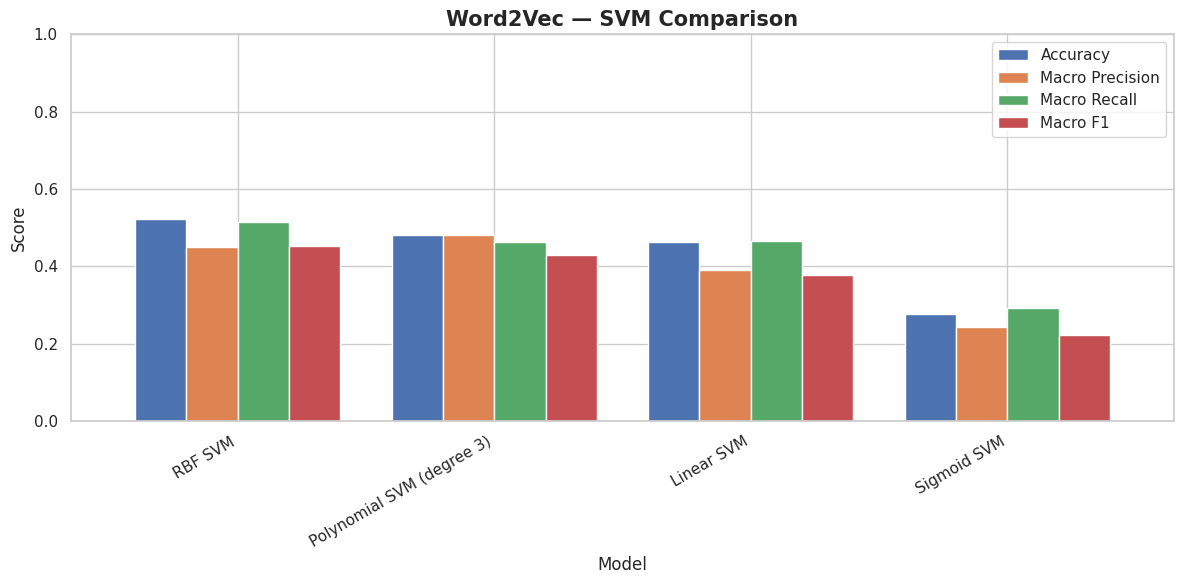

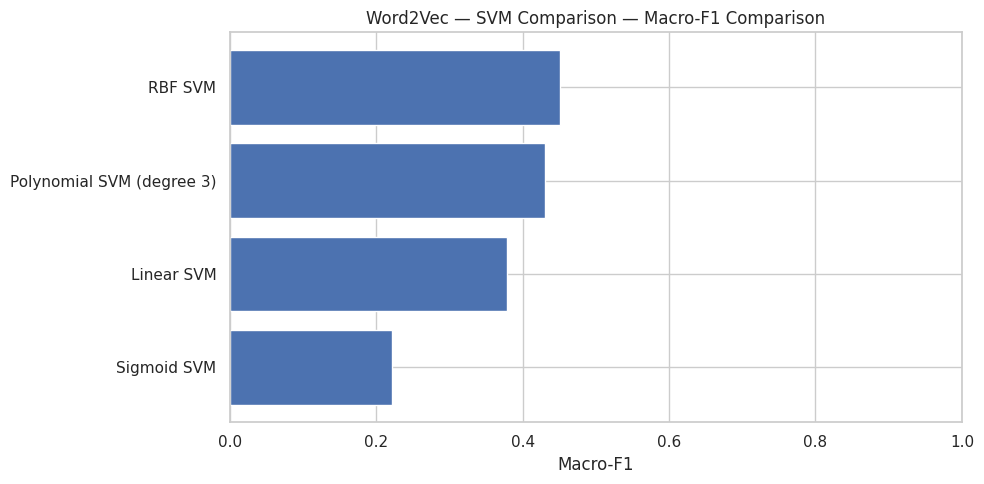

In [42]:

plot_model_results(
    svm_results_df,
    "Word2Vec — SVM Comparison"
)


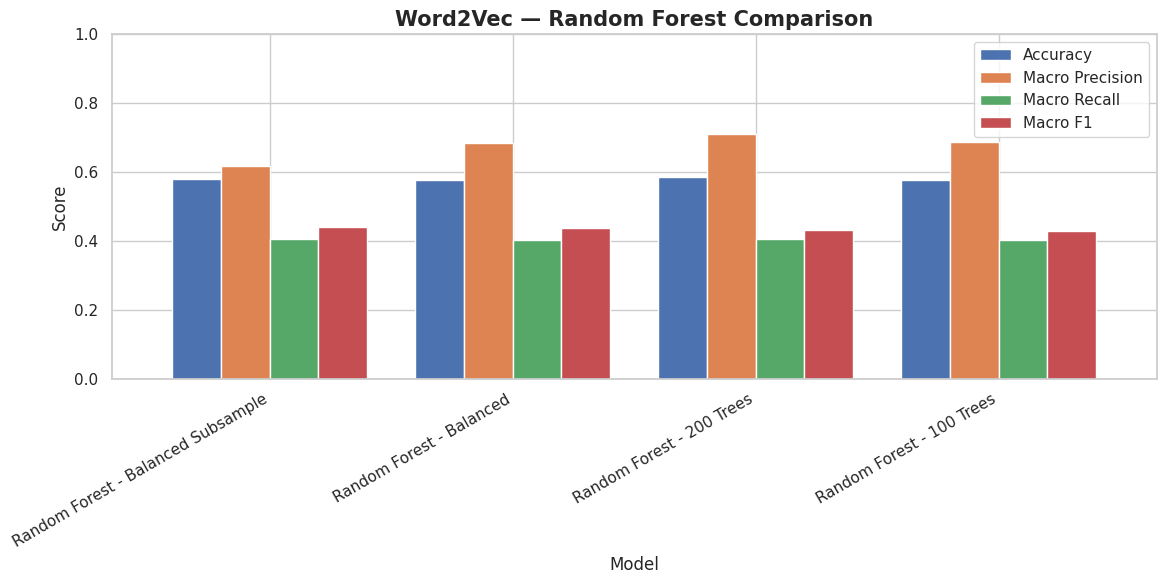

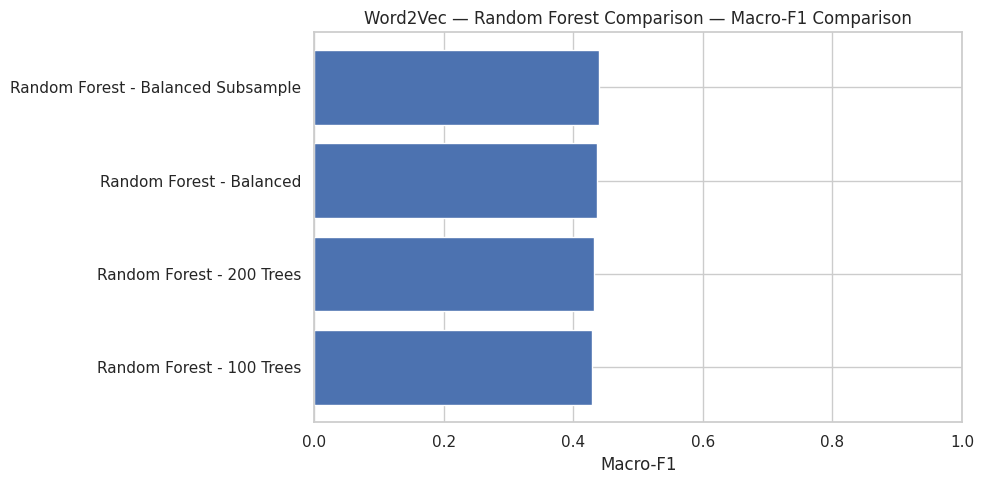

In [43]:

plot_model_results(
    rf_results_df,
    "Word2Vec — Random Forest Comparison"
)


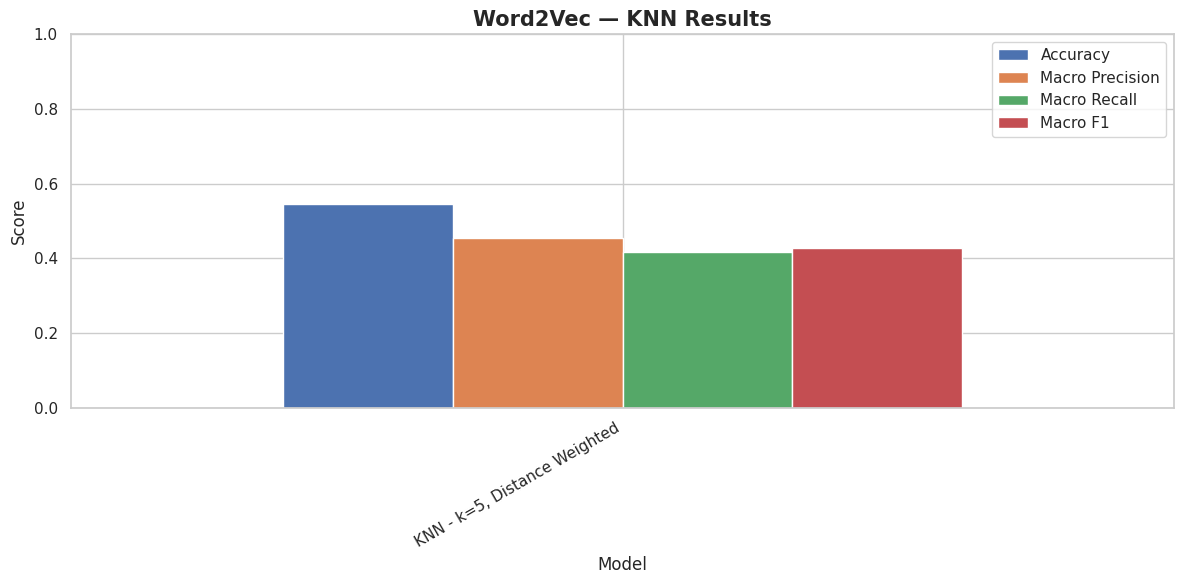

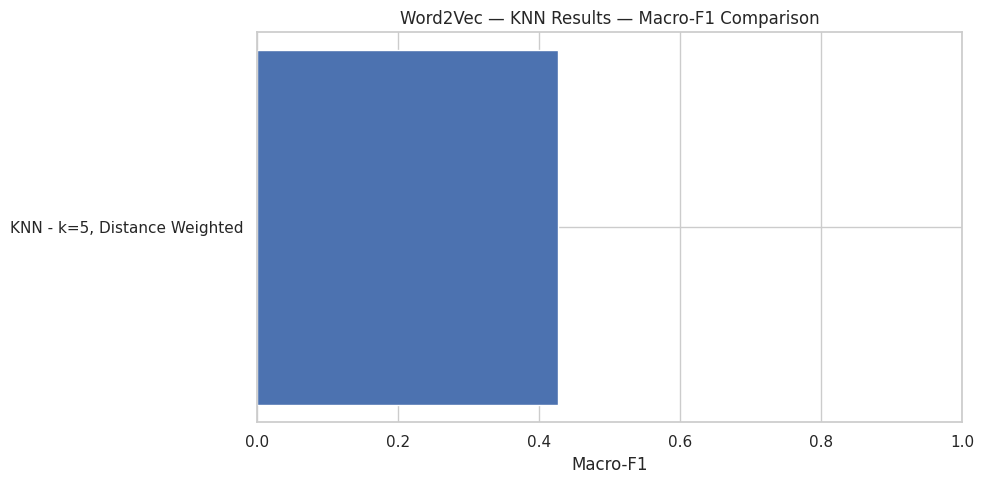

In [45]:

knn_results_df = pd.DataFrame([knn_metrics])

plot_model_results(
    knn_results_df,
    "Word2Vec — KNN Results"
)


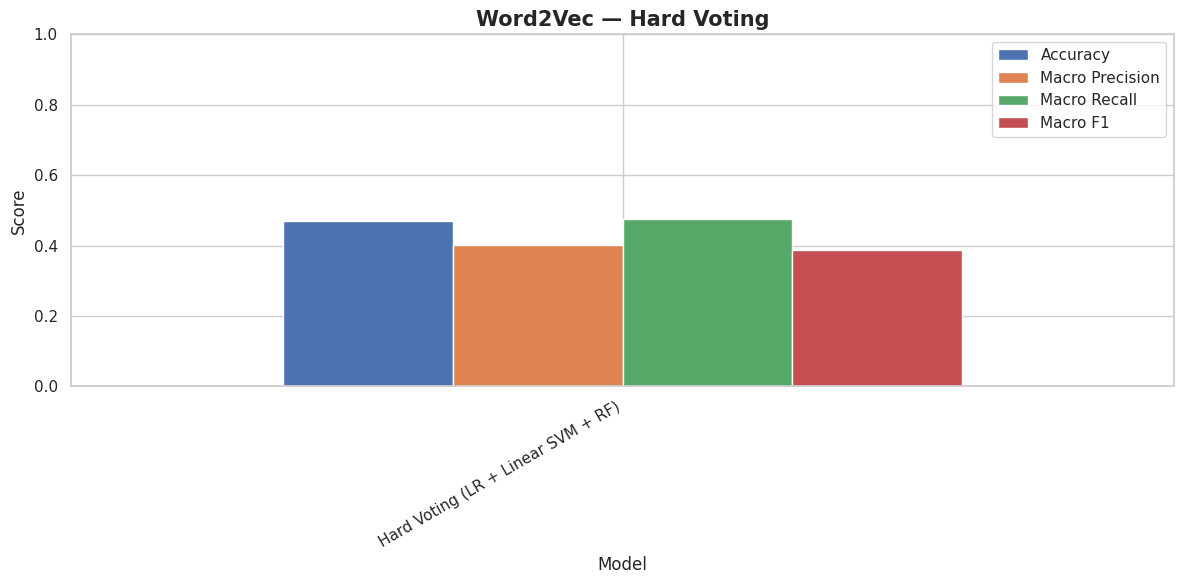

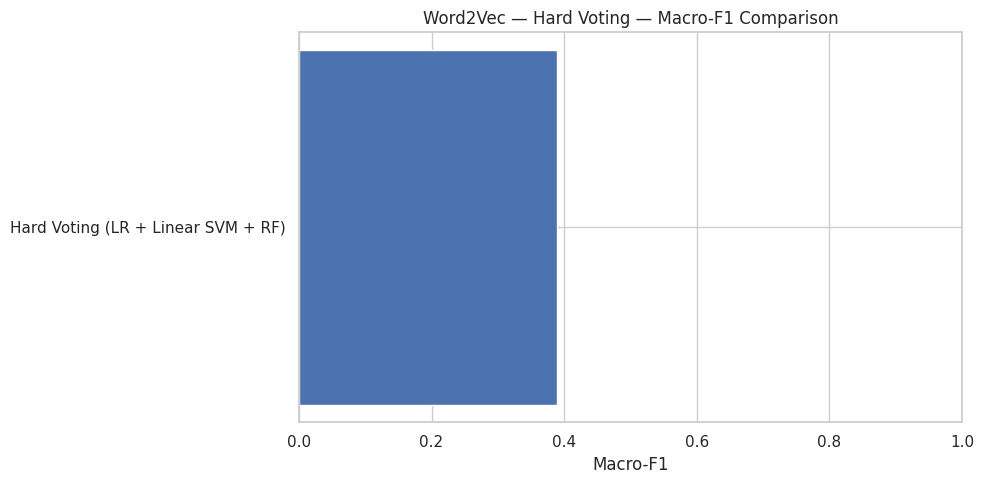

In [46]:

plot_model_results(
    hard_results,
    "Word2Vec — Hard Voting"
)


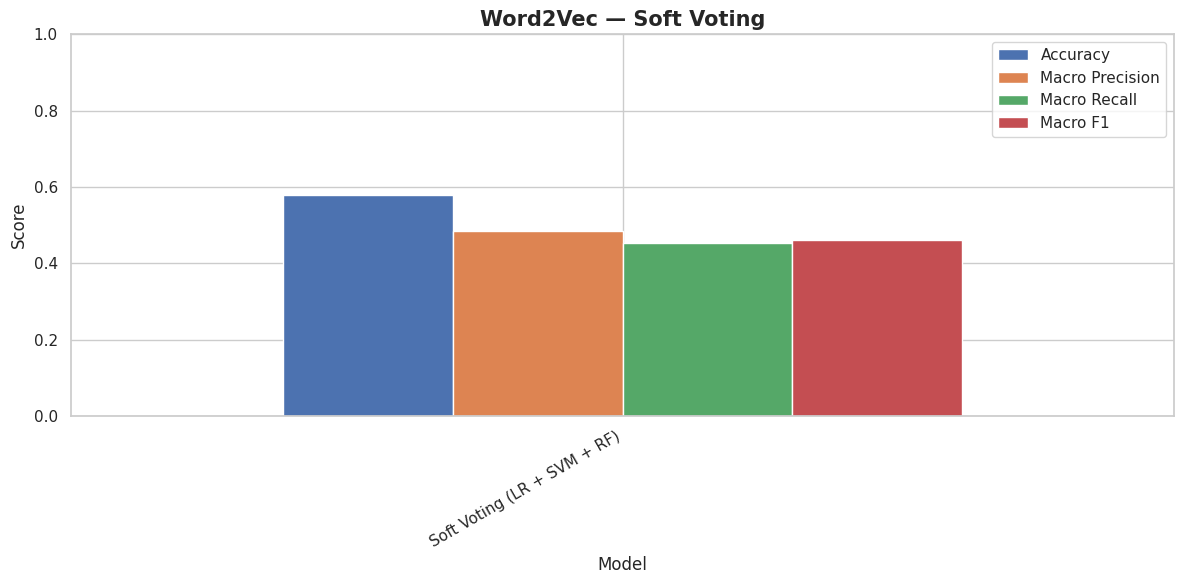

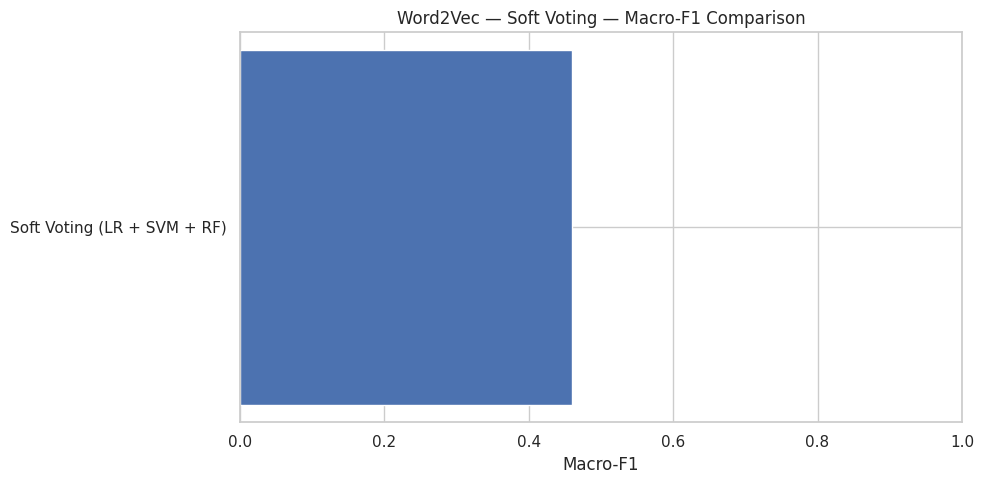

In [47]:

plot_model_results(
    soft_results,
    "Word2Vec — Soft Voting"
)


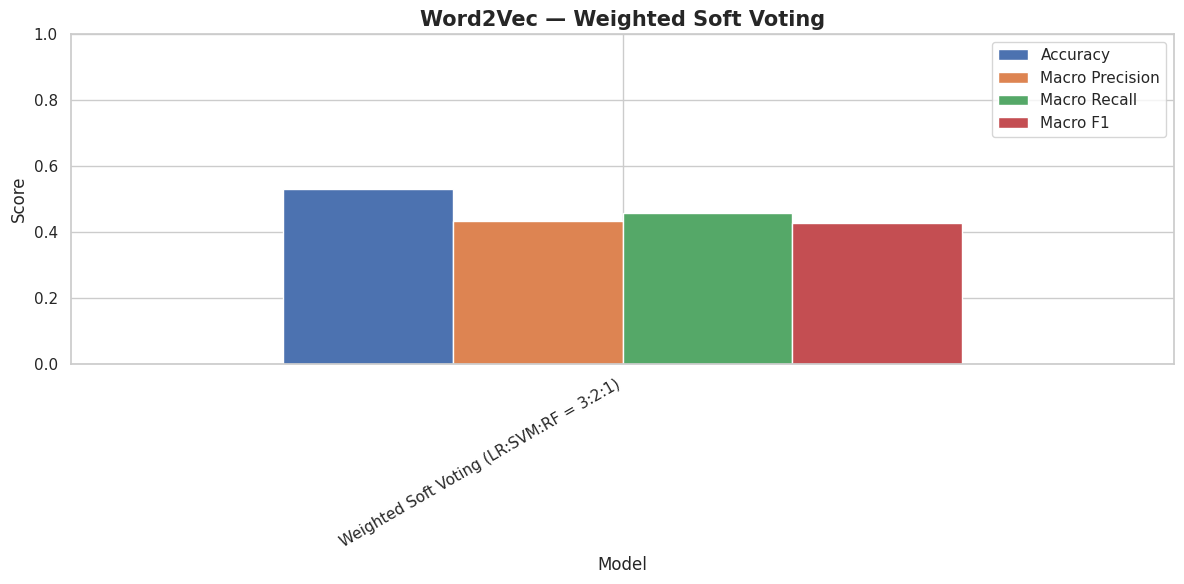

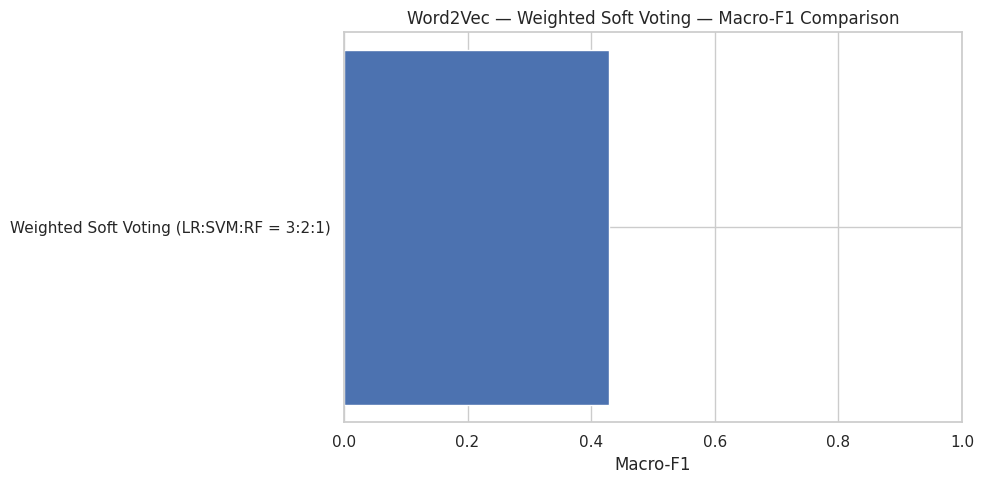

In [48]:

plot_model_results(
    weighted_results,
    "Word2Vec — Weighted Soft Voting"
)


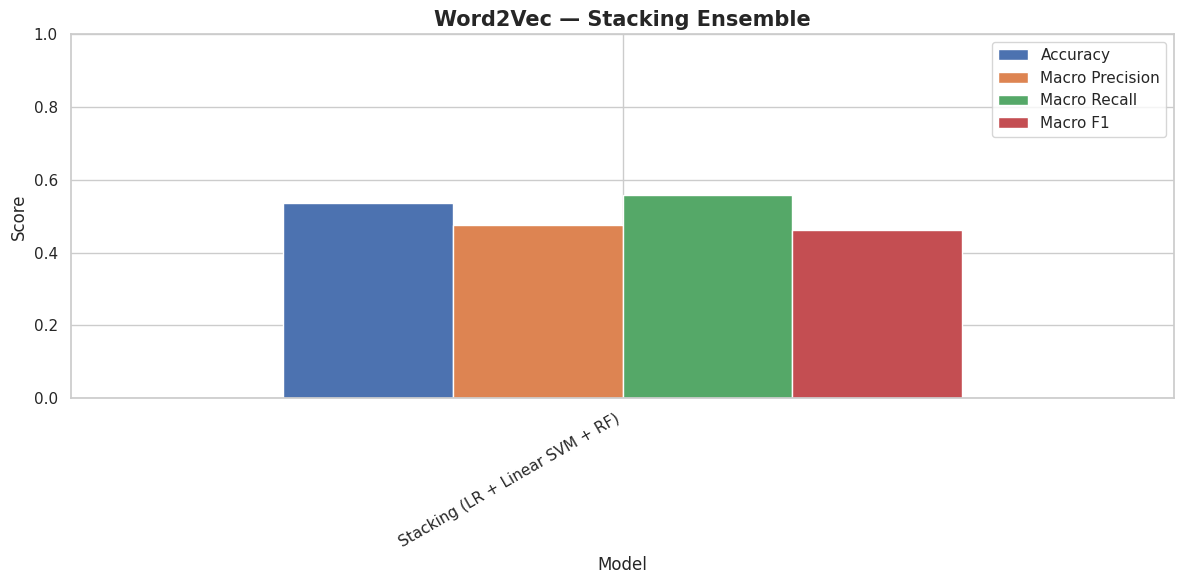

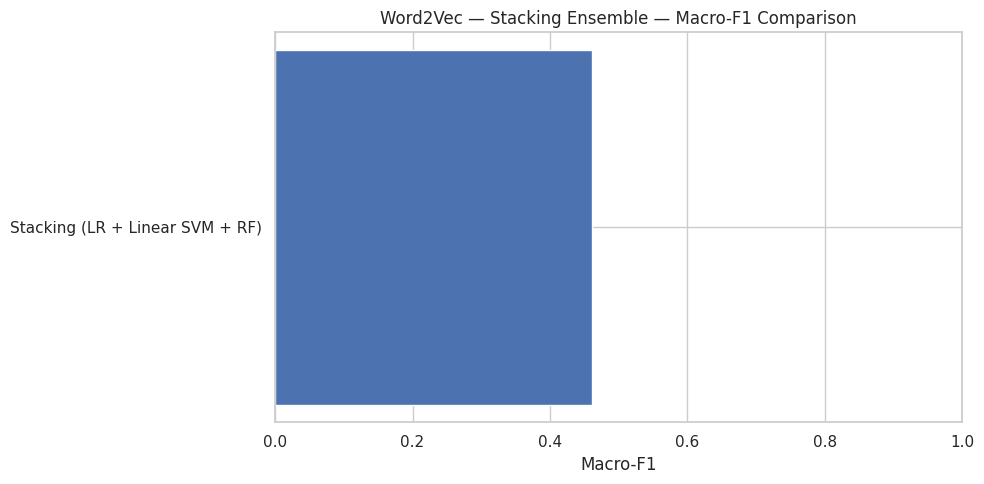

In [49]:

plot_model_results(
    stack_results,
    "Word2Vec — Stacking Ensemble"
)


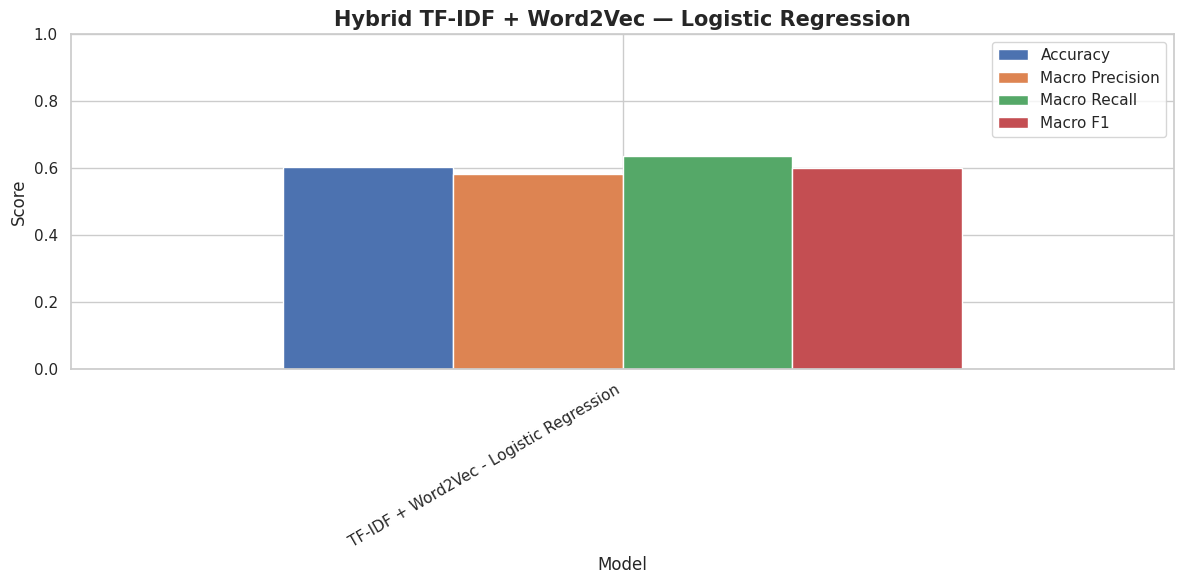

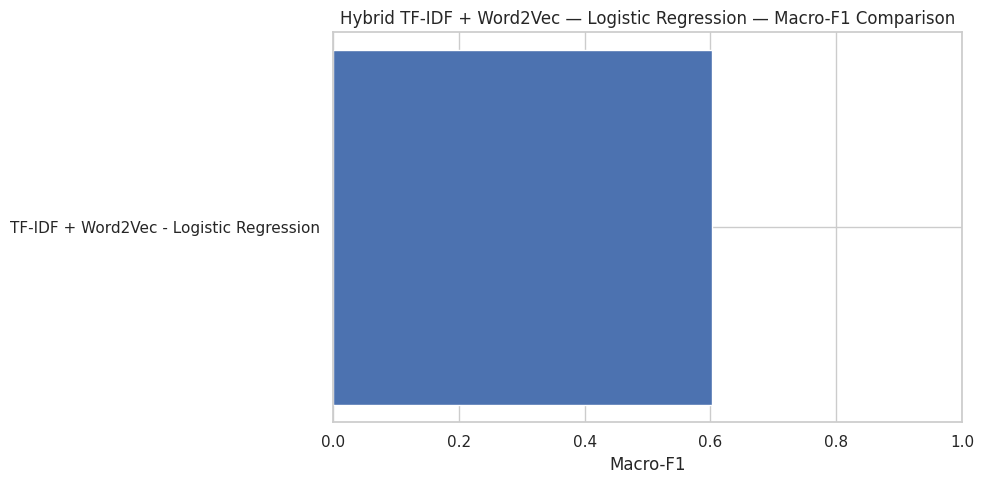

In [50]:

plot_model_results(
    hybrid_lr_results,
    "Hybrid TF-IDF + Word2Vec — Logistic Regression"
)


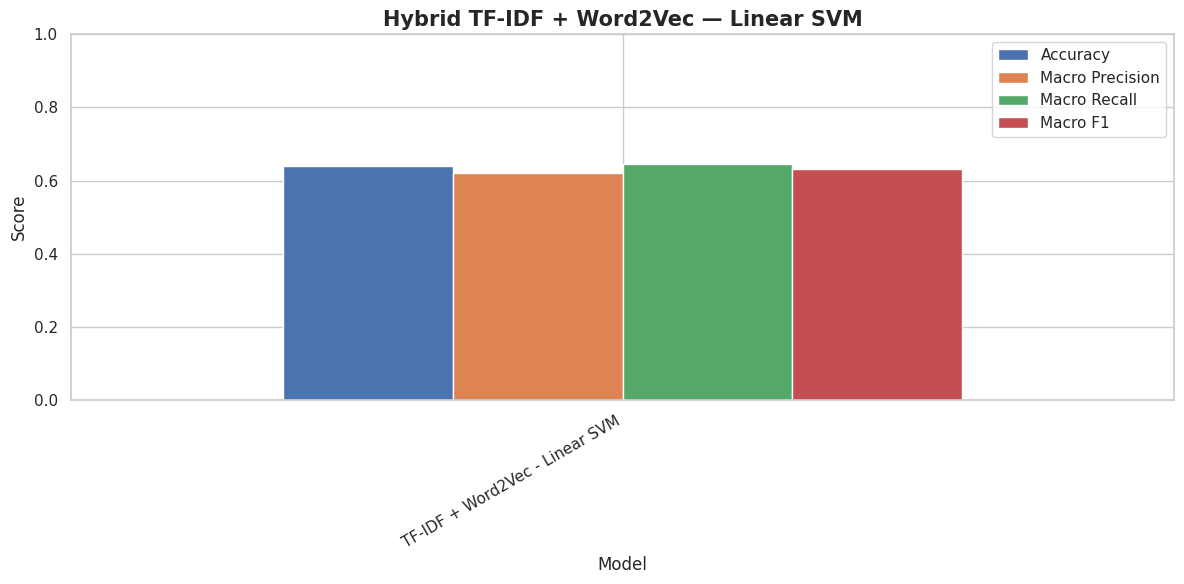

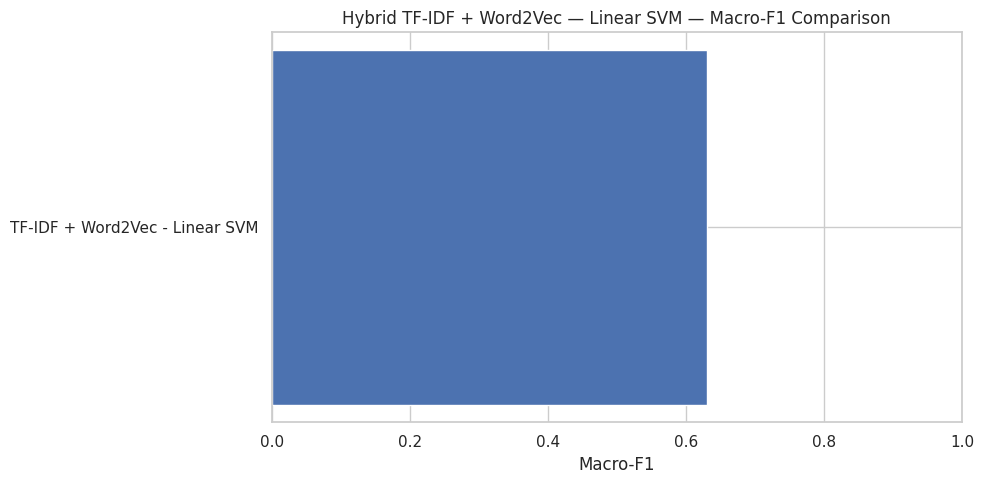

In [51]:

plot_model_results(
    hybrid_svm_results,
    "Hybrid TF-IDF + Word2Vec — Linear SVM"
)


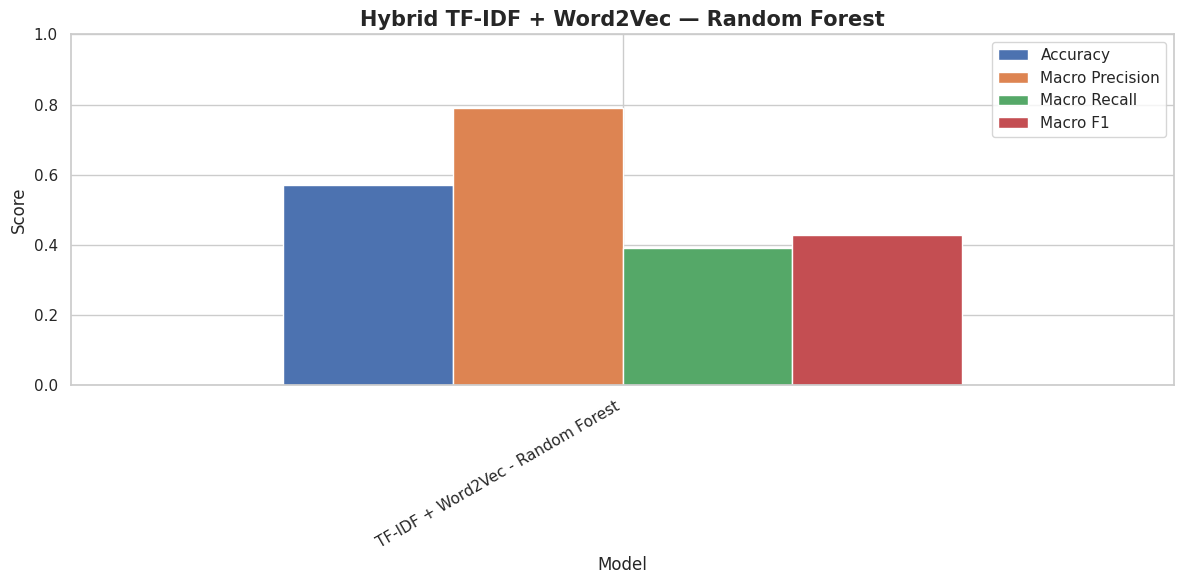

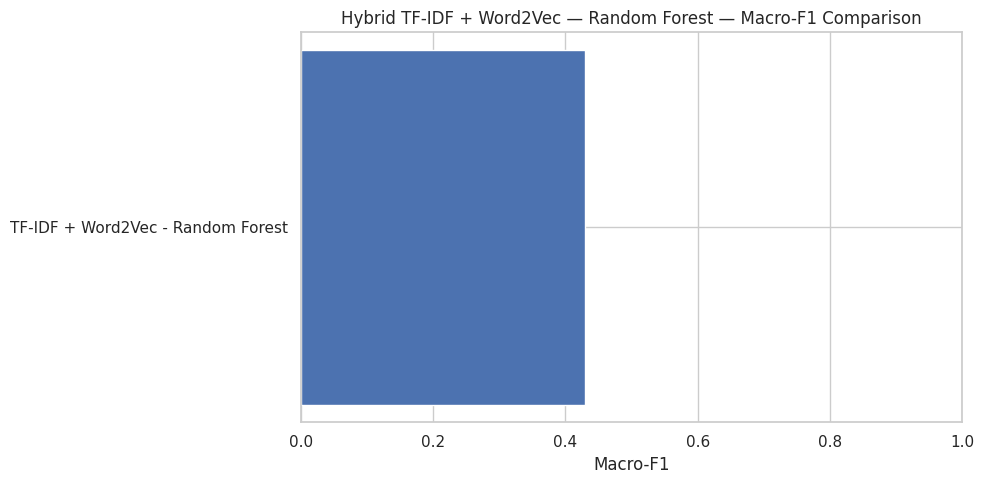

In [52]:

plot_model_results(
    hybrid_rf_results,
    "Hybrid TF-IDF + Word2Vec — Random Forest"
)


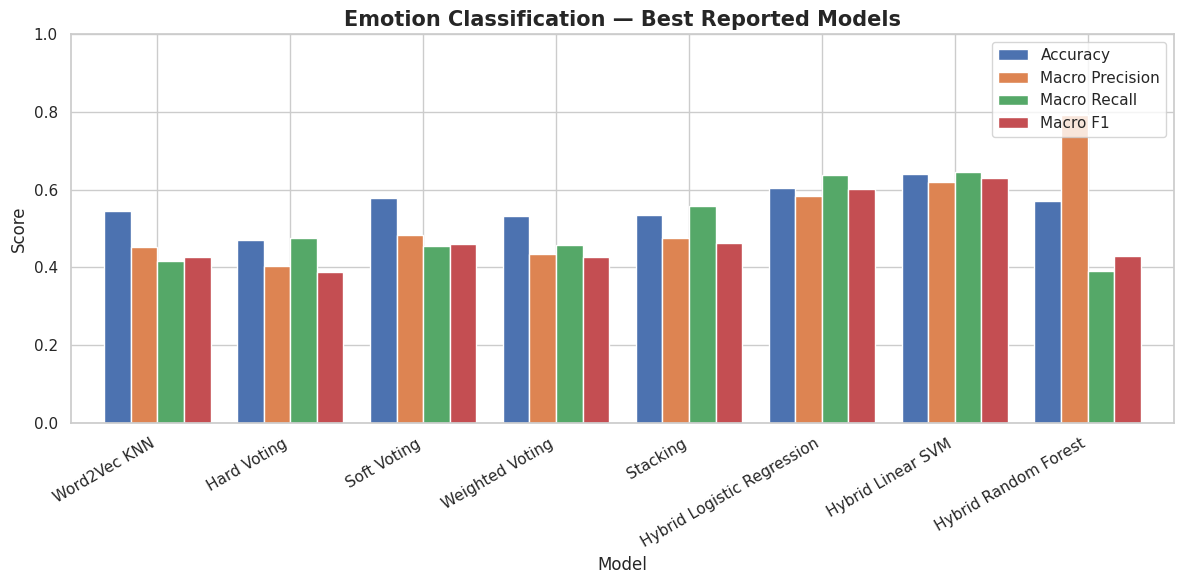

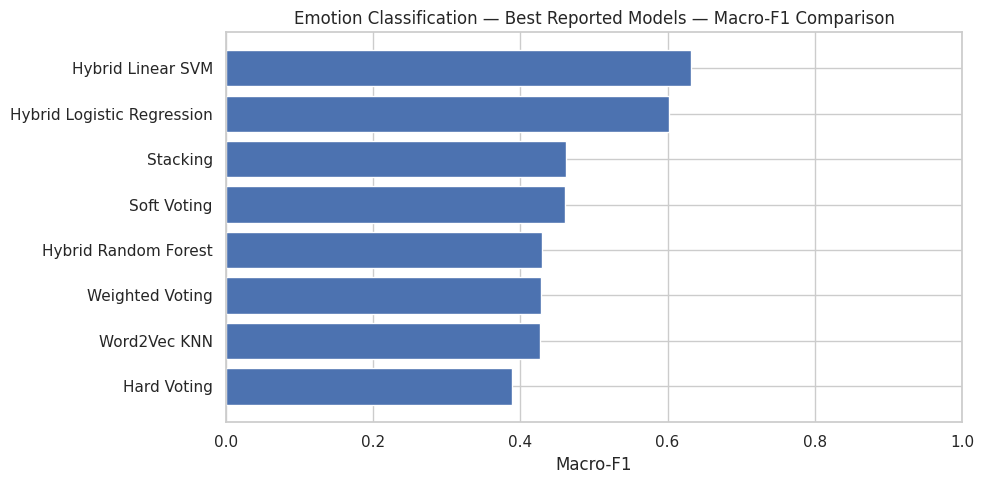

In [53]:

best_models = pd.DataFrame([
    {
        "Model": "Word2Vec KNN",
        "Accuracy": 0.5446,
        "Macro Precision": 0.4532,
        "Macro Recall": 0.4155,
        "Macro F1": 0.4270
    },
    {
        "Model": "Hard Voting",
        "Accuracy": 0.4709,
        "Macro Precision": 0.4030,
        "Macro Recall": 0.4758,
        "Macro F1": 0.3885
    },
    {
        "Model": "Soft Voting",
        "Accuracy": 0.5779,
        "Macro Precision": 0.4834,
        "Macro Recall": 0.4543,
        "Macro F1": 0.4606
    },
    {
        "Model": "Weighted Voting",
        "Accuracy": 0.5314,
        "Macro Precision": 0.4350,
        "Macro Recall": 0.4590,
        "Macro F1": 0.4282
    },
    {
        "Model": "Stacking",
        "Accuracy": 0.5358,
        "Macro Precision": 0.4763,
        "Macro Recall": 0.5592,
        "Macro F1": 0.4620
    },
    {
        "Model": "Hybrid Logistic Regression",
        "Accuracy": 0.6044,
        "Macro Precision": 0.5842,
        "Macro Recall": 0.6379,
        "Macro F1": 0.6017
    },
    {
        "Model": "Hybrid Linear SVM",
        "Accuracy": 0.6397,
        "Macro Precision": 0.6209,
        "Macro Recall": 0.6445,
        "Macro F1": 0.6313
    },
    {
        "Model": "Hybrid Random Forest",
        "Accuracy": 0.5717,
        "Macro Precision": 0.7915,
        "Macro Recall": 0.3904,
        "Macro F1": 0.4295
    }
])

plot_model_results(
    best_models,
    "Emotion Classification — Best Reported Models"
)
